# StripedHyena 2 小型参考变体：先表示蒸馏，再冻结编码器训练判别头

本轮范围：自定义小型 SH2 reference variant，随机初始化；SE/MR/LI/causal rotary
attention 四块，group_dim=1，192维中心表示。不是官方预训练checkpoint，也不是HyenaDNA。
线性头/MLP完整推理参数分别1,505,281/1,582,721，均<2M；训练用投影单独计数，推理时丢弃。

真实教师为已有 NVIDIA Evo 2 40B `blocks.20.mlp.l3`，8192维REF/ALT中心向量。
仅复用既有缓存，不调用任何Evo 2 API、不使用Teacher分类头软标签。
Stage 1：原train中的960条无标签配对用于训练，240条按基因/重叠上下文分组的无标签配对用于选模。
Stage 2：编码器冻结且eval，ClinVar 1200/400用于训练/验证linear和小MLP头。
两个编码器臂是相同初始encoder和表示蒸馏后encoder；同类型头保持相同随机初值。
四个头全部完成后才执行独立evaluate阶段读取400条test，不能根据test调参。
测试集已在历史实验查看过；本轮是小试，不是新的独立临床验证。

项目根目录PowerShell：
```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements-sh2.txt -r requirements-notebook.txt
.\.venv\Scripts\python.exe scripts/run_hyenadna_notebook.py --notebook StripedHyena2_two_stage_experiment.ipynb --output StripedHyena2_two_stage_experiment.executed.ipynb --status outputs/sh2_notebook_execution.json
```

In [1]:
import os, sys, json, hashlib
from pathlib import Path
from datetime import datetime, timezone
ROOT = Path.cwd().resolve()
assert Path(sys.executable).resolve() == (ROOT / ".venv/Scripts/python.exe").resolve()
sys.path.insert(0, str(ROOT / "scripts"))
import torch, numpy as np
from evo2_mvp.utils import save_json, sha256_file
from hyenadna_notebook_support import run_stage
torch.set_num_threads(4)
RUN = Path("outputs/sh2_two_stage_20261104")
DATA = RUN / "data"
TRAINING = RUN / "training"
RUN.mkdir(parents=True, exist_ok=True)
paths = ["configs/stripedhyena2_two_stage.yaml", "data/variants.csv", "data/splits.json",
         "data/GRCh38.fa", "outputs/nvidia_cache/manifest.json", "outputs/teacher/best_teacher.pt",
         "scripts/prepare_sh2_reference.py", "scripts/prepare_two_stage.py", "scripts/test_stripedhyena2.py"]
paths += [p.relative_to(ROOT).as_posix() for p in sorted((ROOT / "src/evo2_mvp").rglob("*.py"))]
hashes = {path: sha256_file(ROOT / path) for path in paths}
IDENTITY = {"identity": hashlib.sha256(json.dumps(hashes, sort_keys=True).encode()).hexdigest(),
            "files_sha256": hashes, "device": "cpu", "python": sys.version, "torch": torch.__version__}
save_json(RUN / "notebook_input_identity.json", IDENTITY)
print("Experiment:", IDENTITY["identity"], "CPU threads:", torch.get_num_threads())

Experiment: 706b915d195b7f940189efa8cb1b746c0986302424be505deef5546777176777 CPU threads: 4


In [2]:
# Initial preparation may create/check the sealed test archive, but it never fits a model.
# Existing prepared data are reused here without opening the sealed test file.
if not (DATA / "metadata.json").is_file():
    run_stage(ROOT, RUN, "data", ["scripts/prepare_two_stage.py", "--variants", "data/variants.csv",
        "--splits", "data/splits.json", "--cache", "outputs/nvidia_cache", "--fasta", "data/GRCh38.fa",
        "--output", str(DATA), "--seed", "42", "--window", "256"], IDENTITY,
        [str(DATA / name) for name in ("metadata.json", "representation_train.npz", "representation_val.npz",
                                      "probe_train.npz", "probe_val.npz")])
metadata = json.loads((DATA / "metadata.json").read_text(encoding="utf-8"))
assert metadata["synthetic"] is False and metadata["status"] == "complete"
for field, path in {"variants_sha256": "data/variants.csv", "splits_sha256": "data/splits.json",
                    "fasta_sha256": "data/GRCh38.fa", "cache_manifest_sha256": "outputs/nvidia_cache/manifest.json"}.items():
    assert metadata["source_hashes"][field] == IDENTITY["files_sha256"][path]
for name, digest in metadata["files_sha256"].items():
    if name == "probe_test.npz":
        continue  # Its actual content/hash is first checked by evaluate after all four probes.
    assert sha256_file(DATA / name) == digest
for name in ("representation_train.npz", "representation_val.npz"):
    with np.load(DATA / name, allow_pickle=False) as archive:
        assert set(archive.files) == {"ref", "alt", "teacher_ref", "teacher_alt", "variant_ids"}
        assert archive["teacher_ref"].shape[1] == 8192
print(json.dumps(metadata["counts"], indent=2))

{
  "outer_train": 1200,
  "outer_val": 400,
  "outer_test": 400,
  "excluded_train_context_overlap": 0,
  "stage1_retained_train_only": 1200,
  "representation_train": 960,
  "representation_val": 240,
  "probe_train": 1200,
  "probe_val": 400,
  "probe_test": 400,
  "connected_representation_groups": 717
}


In [3]:
# Public official source only. All files already downloaded and fixed SHA verified; no model API.
run_stage(ROOT, RUN, "reference", ["scripts/prepare_sh2_reference.py", "--self-check"], IDENTITY,
    ["work/sh2_reference/manifest.json", "work/sh2_reference/reference_checks.json"])
run_stage(ROOT, RUN, "structural", ["scripts/test_stripedhyena2.py", "--output", str(RUN / "phase0")],
    IDENTITY, [str(RUN / "phase0" / n) for n in ("result.json", "embedding_ref.npy", "embedding_alt.npy", "features.npy")])
print(json.loads((RUN / "phase0/result.json").read_text(encoding="utf-8")))

PowerShell: & "D:\Users\60152\learning materials\CISC7021\Report\evo2_pathogenicity_mvp\.venv\Scripts\python.exe" -u scripts/prepare_sh2_reference.py --self-check


{


  "commit": "7b819b8609ce0b29deff79358a294b59d8299d07",


  "device": "cpu",


  "torch_version": "2.7.1+cpu",


  "mathematical_bodies_unmodified": true,


... (65 outputs left out)

  "new_evo2_api_calls": 0,


  "clinical_use": "research_only"


}


{'status': 'passed', 'architecture': 'custom_small_StripedHyena2_reference_variant', 'reference_revision': '7b819b8609ce0b29deff79358a294b59d8299d07', 'initialization': 'seeded_random_not_pretrained', 'teacher_cache_used_in_structural_test': False, 'pathogenicity_score': None, 'window': 256, 'variant_index': 128, 'embedding_shape': [192], 'fused_shape': [576], 'encoder_parameters': 1504704, 'linear_student_parameters': 1505281, 'mlp_student_parameters': 1582721, 'finite': True, 'backward_finite_nonzero': True, 'save_reload_bitwise_equal': True, 'npy_reload_equal': True, 'forward_seconds': 0.04512569999496918, 'device': 'cpu', 'cpu_threads': 4, 'new_evo2_api_calls': 0, 'clinical_use': 'research_only'}


In [4]:
os.environ["RUN_HYENADNA_INTEGRATION"] = "1"
os.environ["RUN_EVO2_INTEGRATION"] = "0"
# Real local Hyena checkpoint and official SH2 equation parity run; live Evo2 API test stays opt-out.
run_stage(ROOT, RUN, "tests", ["-m", "pytest", "-q", "--basetemp", "work/pytest_sh2_full",
    "--junitxml", str(RUN / "junit.xml")], IDENTITY, [str(RUN / "junit.xml")])

PowerShell: & "D:\Users\60152\learning materials\CISC7021\Report\evo2_pathogenicity_mvp\.venv\Scripts\python.exe" -u -m pytest -q --basetemp work/pytest_sh2_full --junitxml outputs\sh2_two_stage_20261104\junit.xml


..........s............................................................. [ 40%]


........................................................................ [ 80%]


..................................                                       [100%]


- generated xml file: D:\Users\60152\learning materials\CISC7021\Report\evo2_pathogenicity_mvp\outputs\sh2_two_stage_20261104\junit.xml -


177 passed, 1 skipped in 75.46s (0:01:15)


{'status': 'completed',
 'signature': {'experiment_identity': '706b915d195b7f940189efa8cb1b746c0986302424be505deef5546777176777',
  'arguments': ['-m',
   'pytest',
   '-q',
   '--basetemp',
   'work/pytest_sh2_full',
   '--junitxml',
   'outputs\\sh2_two_stage_20261104\\junit.xml']},
 'started_at_utc': '2026-11-04T01:25:30.351709+00:00',
 'completed_at_utc': '2026-11-04T01:26:47.876235+00:00',
 'returncode': 0,
 'artifacts_sha256': {'outputs/sh2_two_stage_20261104/junit.xml': 'ccad9cde50a1560a052546efec9be662ad66f3d3fee6c3d5168dbbcc15661090'}}

## Stage 1：纯表示蒸馏

只读取representation_train/val，禁止读取probe文件、ClinVar标签或Teacher分类头。
REF/ALT共享train-only标准化，delta使用独立train-only尺度；教师目标固定，训练学生与两个投影。
无BCE、无输出分布KD。仅用representation-val MSE选encoder并早停。
单独记录ref/alt/delta损失、均值预测基线、学生表示方差及训练/推理参数量。
这只有960条配对，验证的是方法通路，不等于复现基础模型预训练。

In [5]:
args = ["-m", "evo2_mvp.two_stage_student", "--stage", "distill", "--data-dir", str(DATA),
        "--config", "configs/stripedhyena2_two_stage.yaml", "--output", str(TRAINING), "--device", "cpu", "--resume"]
# --resume initializes a fresh run if no saved state exists; otherwise validates and continues it.
run_stage(ROOT, RUN, "distill", args, IDENTITY, [str(TRAINING / name) for name in
    ("initial_encoder.pt", "best_encoder.pt", "last_distillation.pt", "distillation_curve.csv", "distillation_status.json")])
print(json.loads((TRAINING / "distillation_status.json").read_text(encoding="utf-8")))

PowerShell: & "D:\Users\60152\learning materials\CISC7021\Report\evo2_pathogenicity_mvp\.venv\Scripts\python.exe" -u -m evo2_mvp.two_stage_student --stage distill --data-dir outputs\sh2_two_stage_20261104\data --config configs/stripedhyena2_two_stage.yaml --output outputs\sh2_two_stage_20261104\training --device cpu --resume


{"event": "representation_epoch", "epoch": 1, "train_ref": 1.1050217817227046, "train_alt": 1.0025953282912572, "train_delta": 1.0092919230461121, "train_total": 2.06310050090154, "train_gradient_norm_before_clip": 0.15820414858559767, "val_ref": 1.0901700258255005, "val_alt": 0.966908621788025, "val_delta": 0.9206438382466634, "val_total": 1.949183185895284, "val_embedding_mean_std": 0.3620363771915436, "val_embedding_mean_variance": 0.13812793791294098, "val_embedding_mean_norm": 13.748682975769043, "val_delta_embedding_mean_std": 0.5701724886894226, "val_delta_embedding_mean_norm": 8.264123916625977, "epoch_seconds": 78.60518369999772}


{"event": "representation_epoch", "epoch": 2, "train_ref": 1.0302255958318711, "train_alt": 0.918947238723437, "train_delta": 0.8745009278257688, "train_total": 1.8490873416264852, "train_gradient_norm_before_clip": 0.10413831546902656, "val_ref": 1.0691728472709656, "val_alt": 0.9415768663088481, "val_delta": 0.8906334002812704, "val_total": 1.89600830078125, "val_embedding_mean_std": 0.4058589041233063, "val_embedding_mean_variance": 0.17675046622753143, "val_embedding_mean_norm": 13.712248802185059, "val_delta_embedding_mean_std": 0.6099543571472168, "val_delta_embedding_mean_norm": 8.837186813354492, "epoch_seconds": 74.04873879998922}


{"event": "representation_epoch", "epoch": 3, "train_ref": 1.0193034390608469, "train_alt": 0.904611932237943, "train_delta": 0.8627015034357707, "train_total": 1.8246591866016388, "train_gradient_norm_before_clip": 0.10435229328771432, "val_ref": 1.073722811539968, "val_alt": 0.9365456024805705, "val_delta": 0.8888207038243612, "val_total": 1.8939549207687378, "val_embedding_mean_std": 0.4127654731273651, "val_embedding_mean_variance": 0.1827588528394699, "val_embedding_mean_norm": 13.669400215148926, "val_delta_embedding_mean_std": 0.6217442750930786, "val_delta_embedding_mean_norm": 9.042829513549805, "epoch_seconds": 73.41826720000245}


{"event": "representation_epoch", "epoch": 4, "train_ref": 1.017727592587471, "train_alt": 0.9018111517031987, "train_delta": 0.8596523076295852, "train_total": 1.8194216946760813, "train_gradient_norm_before_clip": 0.10611863570908706, "val_ref": 1.0680182973543804, "val_alt": 0.9321829279263815, "val_delta": 0.8883261998494466, "val_total": 1.8884267965952555, "val_embedding_mean_std": 0.4068642854690552, "val_embedding_mean_variance": 0.1794191151857376, "val_embedding_mean_norm": 13.622119903564453, "val_delta_embedding_mean_std": 0.6081333160400391, "val_delta_embedding_mean_norm": 8.880172729492188, "epoch_seconds": 72.92554529999325}


{"event": "representation_epoch", "epoch": 5, "train_ref": 1.0157084693511327, "train_alt": 0.898104636867841, "train_delta": 0.8577921494841576, "train_total": 1.8146987060705821, "train_gradient_norm_before_clip": 0.10887050641079744, "val_ref": 1.0630770961443583, "val_alt": 0.9322790463765462, "val_delta": 0.8866683125495911, "val_total": 1.884346357981364, "val_embedding_mean_std": 0.4094829559326172, "val_embedding_mean_variance": 0.18049274384975433, "val_embedding_mean_norm": 13.573258399963379, "val_delta_embedding_mean_std": 0.6150880455970764, "val_delta_embedding_mean_norm": 9.03862476348877, "epoch_seconds": 74.76935990000493}


... (8 outputs left out)

{"event": "representation_epoch", "epoch": 14, "train_ref": 0.9341895739237468, "train_alt": 0.8334309284885725, "train_delta": 0.8092143664757411, "train_total": 1.693024609486262, "train_gradient_norm_before_clip": 0.5370922982692719, "val_ref": 1.077690315246582, "val_alt": 0.9419556458791097, "val_delta": 0.8878150423367818, "val_total": 1.8976380189259847, "val_embedding_mean_std": 0.47923651337623596, "val_embedding_mean_variance": 0.24259470403194427, "val_embedding_mean_norm": 12.919678688049316, "val_delta_embedding_mean_std": 0.6258318424224854, "val_delta_embedding_mean_norm": 8.944942474365234, "epoch_seconds": 72.44994830001087}


{"event": "representation_epoch", "epoch": 15, "train_ref": 0.9114556570847829, "train_alt": 0.8169443408648173, "train_delta": 0.7934919014573097, "train_total": 1.6576918939749399, "train_gradient_norm_before_clip": 0.6428979883591334, "val_ref": 1.0791636943817138, "val_alt": 0.9546168287595113, "val_delta": 0.8978270888328552, "val_total": 1.9147173563639324, "val_embedding_mean_std": 0.5046035051345825, "val_embedding_mean_variance": 0.26832789182662964, "val_embedding_mean_norm": 12.835718154907227, "val_delta_embedding_mean_std": 0.650549590587616, "val_delta_embedding_mean_norm": 9.323549270629883, "epoch_seconds": 72.90597890000208}


{"status": "completed", "stage": "distill", "best_epoch": 10, "encoder_sha256": "c803719d7adefc6a152794f682c725ee7e7b33eedf67c4831826208cba01b76e"}


{'stage': 'representation_distillation', 'protocol': {'configuration_sha256': 'b2d1414d5ef33f048733a38620cdd58d629f422af235a67c95955d99f1fb8016', 'prepared_metadata_sha256': 'a724bd473999a8b3d799366a9a6603fea6ead38842747ed56f4e6f75007ae886', 'representation_files_sha256': {'representation_train.npz': 'd6820bc5afb939ef5087670b8a54c1514bff837bc4dbcd87c6f8c6d33cefcd04', 'representation_val.npz': '7b4eb1b02bc86e2f205e676cefb0263a9f2e24907c1b08aba0a48fb93bbe7ae7'}, 'train_ids_sha256': 'b503db493d56b2beff58bcd30de949e650e634db5da96e1869d1001819af84c1', 'val_ids_sha256': '8034b359c1c092c90c6f7b242983e597ac0b583649fc1702836df2d7928a1024'}, 'labels_used': False, 'clinical_validation_test_used': False, 'n_train': 960, 'n_val': 240, 'teacher_dim': 8192, 'projector_count': 2, 'training_only_projection_parameters': 3162112, 'total_training_parameters': 4666816, 'inference_student_parameters': 1505281, 'constant_mean_baseline': {'train': {'ref': 1.0493961572647095, 'alt': 0.9506037831306458, 'delta'

## Stage 2：冻结编码器的判别探针

分别使用蒸馏前/后的冻结编码器提取`concat(ref,alt,alt-ref)`。
每种编码器上分别训练linear和MLP，共四个模型；同类型头同初始权重、同训练参数。
feature scaler只由probe train拟合，按clinical val BCE选择头；编码器全程eval且无梯度。
记录前后encoder SHA，防止判别训练悄悄微调encoder。

In [6]:
ARMS = ("random_linear", "distilled_linear", "random_mlp", "distilled_mlp")
run_stage(ROOT, RUN, "probes", ["-m", "evo2_mvp.two_stage_student", "--stage", "probes", "--data-dir", str(DATA),
    "--config", "configs/stripedhyena2_two_stage.yaml", "--output", str(TRAINING), "--device", "cpu", "--resume"], IDENTITY,
    [str(TRAINING / "probes_status.json")] + [str(TRAINING / "probes" / arm / "best_student.pt") for arm in ARMS])
print(json.loads((TRAINING / "probes_status.json").read_text(encoding="utf-8")))

PowerShell: & "D:\Users\60152\learning materials\CISC7021\Report\evo2_pathogenicity_mvp\.venv\Scripts\python.exe" -u -m evo2_mvp.two_stage_student --stage probes --data-dir outputs\sh2_two_stage_20261104\data --config configs/stripedhyena2_two_stage.yaml --output outputs\sh2_two_stage_20261104\training --device cpu --resume


{"event": "frozen_probe_epoch", "arm": "random", "head_kind": "linear", "epoch": 1, "train_loss": 0.702821159362793, "val_loss": 0.6854265332221985, "epoch_seconds": 0.061582199996337295}


{"event": "frozen_probe_epoch", "arm": "random", "head_kind": "linear", "epoch": 2, "train_loss": 0.6818743721644084, "val_loss": 0.6898534893989563, "epoch_seconds": 0.06010909999895375}


{"event": "frozen_probe_epoch", "arm": "random", "head_kind": "linear", "epoch": 3, "train_loss": 0.6752165921529134, "val_loss": 0.6737722754478455, "epoch_seconds": 0.049024799998733215}


{"event": "frozen_probe_epoch", "arm": "random", "head_kind": "linear", "epoch": 4, "train_loss": 0.6658547083536784, "val_loss": 0.6959313750267029, "epoch_seconds": 0.04880369998863898}


{"event": "frozen_probe_epoch", "arm": "random", "head_kind": "linear", "epoch": 5, "train_loss": 0.6661487007141114, "val_loss": 0.6608434915542603, "epoch_seconds": 0.055298499995842576}


... (78 outputs left out)

    "distilled_mlp": "dd296b077d9d52600c5e24c647521a7a54541a416b6dd0c9988f5cc6a8de5717"


  }


}


{'stage': 'frozen_probes', 'status': 'completed', 'prepared_metadata_sha256': 'a724bd473999a8b3d799366a9a6603fea6ead38842747ed56f4e6f75007ae886', 'configuration_sha256': 'b2d1414d5ef33f048733a38620cdd58d629f422af235a67c95955d99f1fb8016', 'predefined_probes': ['random_linear', 'distilled_linear', 'random_mlp', 'distilled_mlp'], 'completed': ['random_linear', 'distilled_linear', 'random_mlp', 'distilled_mlp'], 'clinical_test_opened': False, 'common_initial_encoder_sha256': '824f3d0c8bf6648066e569650d1d959018f617b9256802a8c0d94475f8c713e8', 'all_probes_trained_before_test': True, 'checkpoints_sha256': {'random_linear': 'c70ab761e078152f383f0f03bf39a41a92cc8543a4c53f7468b2b8a035ee1f94', 'distilled_linear': 'bcbdce7a3ac5a686c58dfe75c8adfa615bf29fd95c0cbbb6f1734bf04de833e9', 'random_mlp': 'f6b7c7af8ee16d8e976770d96ada07a8883acf44816818bd707027ee249872db', 'distilled_mlp': 'dd296b077d9d52600c5e24c647521a7a54541a416b6dd0c9988f5cc6a8de5717'}}


PowerShell: & "D:\Users\60152\learning materials\CISC7021\Report\evo2_pathogenicity_mvp\.venv\Scripts\python.exe" -u -m evo2_mvp.two_stage_student --stage evaluate --data-dir outputs\sh2_two_stage_20261104\data --config configs/stripedhyena2_two_stage.yaml --output outputs\sh2_two_stage_20261104\training --device cpu


{


  "status": "evaluated_all_predefined_probes",


  "models": {


    "random_linear": {


      "test": {


... (130 outputs left out)

  "selection": "no_selection_between_the_four_models_using_test",


  "clinical_use": "research_only"


}


,model,auroc,auprc,f1,recall,brier_score,n,positives
0,random_linear,0.581025,0.213756,0.131148,0.083333,0.171334,400,48
1,distilled_linear,0.669744,0.221535,0.279070,0.250000,0.158501,400,48
2,random_mlp,0.651515,0.220320,0.000000,0.000000,0.105768,400,48
3,distilled_mlp,0.700107,0.232334,0.070175,0.041667,0.104259,400,48


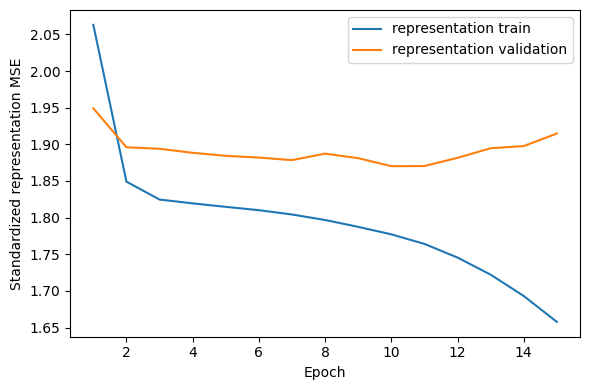

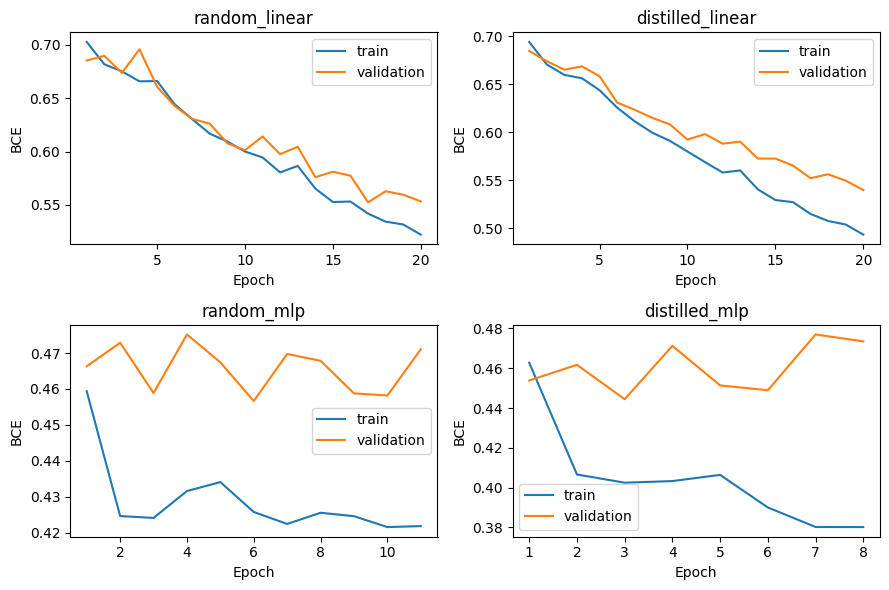

In [7]:
# All four heads must exist and be marked complete before this command can open probe_test.npz.
run_stage(ROOT, RUN, "evaluate", ["-m", "evo2_mvp.two_stage_student", "--stage", "evaluate", "--data-dir", str(DATA),
    "--config", "configs/stripedhyena2_two_stage.yaml", "--output", str(TRAINING), "--device", "cpu"], IDENTITY,
    [str(TRAINING / "two_stage_test_comparison.json"), str(TRAINING / "two_stage_test_predictions.csv")]
    + [str(TRAINING / "probes" / arm / "test_metrics.json") for arm in ARMS])
import pandas as pd
from IPython.display import display
rows = []
for arm in ARMS:
    metrics = json.loads((TRAINING / "probes" / arm / "test_metrics.json").read_text(encoding="utf-8"))
    rows.append({"model": arm, **{key: metrics[key] for key in ("auroc", "auprc", "f1", "recall", "brier_score", "n", "positives")}})
table = pd.DataFrame(rows)
table.to_csv(RUN / "model_comparison.csv", index=False)
display(table)
import matplotlib.pyplot as plt
history = pd.read_csv(TRAINING / "distillation_curve.csv")
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history.epoch, history.train_total, label="representation train")
ax.plot(history.epoch, history.val_total, label="representation validation")
ax.set(xlabel="Epoch", ylabel="Standardized representation MSE")
ax.legend()
fig.tight_layout()
fig.savefig(RUN / "representation_training_curve.png", dpi=150)
display(fig)
plt.close(fig)
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for arm, ax in zip(ARMS, axes.flat):
    curve = pd.read_csv(TRAINING / "probes" / arm / "training_curve.csv")
    ax.plot(curve.epoch, curve.train_loss, label="train")
    ax.plot(curve.epoch, curve.val_loss, label="validation")
    ax.set(title=arm, xlabel="Epoch", ylabel="BCE")
    ax.legend()
fig.tight_layout()
fig.savefig(RUN / "probe_training_curves.png", dpi=150)
display(fig)
plt.close(fig)

In [8]:
# Predetermined demonstration model: distilled_linear. Never select the example model by test performance.
selected = TRAINING / "probes/distilled_linear/best_student.pt"
for name in ("prediction", "prediction_reloaded"):
    run_stage(ROOT, RUN, name, ["-m", "evo2_mvp.inference", "--fasta", "data/GRCh38.fa", "--chrom", "1",
        "--pos", "926029", "--ref", "C", "--alt", "T", "--student", str(selected), "--device", "cpu", "--cpu-threads", "4",
        "--output", str(RUN / f"{name}.json")], IDENTITY, [str(RUN / f"{name}.json")])
prediction = json.loads((RUN / "prediction.json").read_text(encoding="utf-8"))
assert prediction == json.loads((RUN / "prediction_reloaded.json").read_text(encoding="utf-8"))
assert prediction["teacher_score"] is None and prediction["clinical_use"] == "research_only"
print(json.dumps(prediction, indent=2))

PowerShell: & "D:\Users\60152\learning materials\CISC7021\Report\evo2_pathogenicity_mvp\.venv\Scripts\python.exe" -u -m evo2_mvp.inference --fasta data/GRCh38.fa --chrom 1 --pos 926029 --ref C --alt T --student outputs\sh2_two_stage_20261104\training\probes\distilled_linear\best_student.pt --device cpu --cpu-threads 4 --output outputs\sh2_two_stage_20261104\prediction.json


{


  "variant_id": "1-926029-C-T",


  "genome_build": "GRCh38",


  "teacher_score": null,


  "student_score": 0.291105717420578,


... (15 outputs left out)

  "calibration_status": "not_calibrated",


  "clinical_use": "research_only"


}


{
  "variant_id": "1-926029-C-T",
  "genome_build": "GRCh38",
  "teacher_score": null,
  "student_score": 0.291105717420578,
  "student_predictive_entropy": 0.603138757614597,
  "ensemble_std": null,
  "calibrated_score": null,
  "calibration_status": "not_calibrated",
  "clinical_use": "research_only"
}


In [9]:
from evo2_mvp.models import build_student, load_checkpoint
from evo2_mvp.distill_student import model_state_sha256
summaries = {}
for arm in ARMS:
    checkpoint = load_checkpoint(TRAINING / "probes" / arm / "best_student.pt")
    model = build_student(checkpoint)
    assert sum(p.numel() for p in model.parameters()) < 2_000_000
    assert all(torch.isfinite(t).all() for t in model.state_dict().values())
    summaries[arm] = {"checkpoint_sha256": sha256_file(TRAINING / "probes" / arm / "best_student.pt"),
                      "parameters": sum(p.numel() for p in model.parameters()),
                      "encoder_sha256": model_state_sha256(model.encoder)}
assert summaries["random_linear"]["encoder_sha256"] == summaries["random_mlp"]["encoder_sha256"]
assert summaries["distilled_linear"]["encoder_sha256"] == summaries["distilled_mlp"]["encoder_sha256"]
assert summaries["random_linear"]["encoder_sha256"] != summaries["distilled_linear"]["encoder_sha256"]
assert sha256_file("outputs/teacher/best_teacher.pt") == IDENTITY["files_sha256"]["outputs/teacher/best_teacher.pt"]
report = {"status": "completed", "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "experiment_identity": IDENTITY["identity"], "architecture": "custom_small_SH2_reference_variant",
    "initialization": "random_then_real_representation_distillation", "counts": metadata["counts"],
    "models": summaries, "test_metrics": rows, "standalone_prediction": prediction,
    "independent_reload_predictions_identical": True, "teacher_unchanged": True, "new_evo2_api_calls": 0,
    "limitations": ["single seed", "only 960 representation-training pairs", "center-only teacher targets",
                    "historically examined test cohort", "custom SH2 scale/schedule, not official pretrained weights"],
    "clinical_use": "research_only"}
save_json(RUN / "run_report.json", report)
print("Completed:", RUN / "run_report.json")

Completed: outputs\sh2_two_stage_20261104\run_report.json
